# 05 · Explaining the boosted Cox model (SHAP)

The XGBoost Cox model from `04_models` is the best model (C 0.699). This notebook explains it with
**exact TreeSHAP** values from XGBoost itself (`pred_contribs`), which handle the native
categorical features (case category, district, judge position) exactly.

How to read the numbers: SHAP values add up to the model's **log hazard** for a case. A value of
+0.3 means that feature multiplies the decision rate by e^0.3 = 1.35× (decided **sooner**); −0.3
means 0.74× (decided **later**). Plots show these multipliers, so 1× is "no effect" and above 1
is faster, as in the Week 3 district chart. Values are relative to the average case.

Explained on a random 20k sample of 2016–2018 filings (the test period).

In [1]:
import time
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import numpy as np
import pandas as pd

from court_delay import models as M
from court_delay.config import DATA, ROOT

FIG = ROOT / "reports" / "figures"
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#a9a8a3"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "lines.linewidth": 2, "legend.frameon": False,
})
LABELS = {"case_category": "Case category", "queue_ratio": "Queue ratio", "district_name": "District",
          "judge_position": "Court / judge position", "clearance_1y": "Clearance rate",
          "log_inflow": "Inflow (filings, past year)", "log_backlog": "Backlog (pending, past 2 years)",
          "is_criminal": "Criminal case", "court_system": "Mumbai / statewide court system",
          "clearance_missing": "Clearance unknown"}


def finish(fig, name):
    fig.text(0.01, -0.03, "Source: Development Data Lab e-Courts data, Maharashtra. XGBoost Cox model trained on "
             "2012–2015 filings; exact TreeSHAP on 20k cases filed 2016–2018.", fontsize=7.5, color=INK2)
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


def mult_axis(axis, ticks=(0.25, 0.5, 0.67, 1, 1.5, 2, 4, 8)):
    axis.set_major_locator(mt.FixedLocator(ticks))
    axis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}×"))
    axis.set_minor_locator(mt.NullLocator())

In [2]:
model = M.XGBCox.load(DATA / "models" / "eval")
_, test = M.split(M.load())
ev = test.sample(20_000, random_state=0).reset_index(drop=True)
del test
t = time.time()
sv = model.shap(ev)
print(f"SHAP for {len(ev):,} cases in {time.time() - t:.0f}s, {model.booster.best_iteration + 1} trees")
gap = np.abs(sv.sum(axis=1) - model._margin(ev)).max()
print(f"rows sum to the model margin (max gap {gap:.1e})")
feat = sv.drop(columns="bias")

SHAP for 20,000 cases in 66s, 867 trees


rows sum to the model margin (max gap 1.0e-05)


## 1. Which features matter most

Mean absolute SHAP value: how far, on average, each feature moves a case's decision rate away
from the average case.

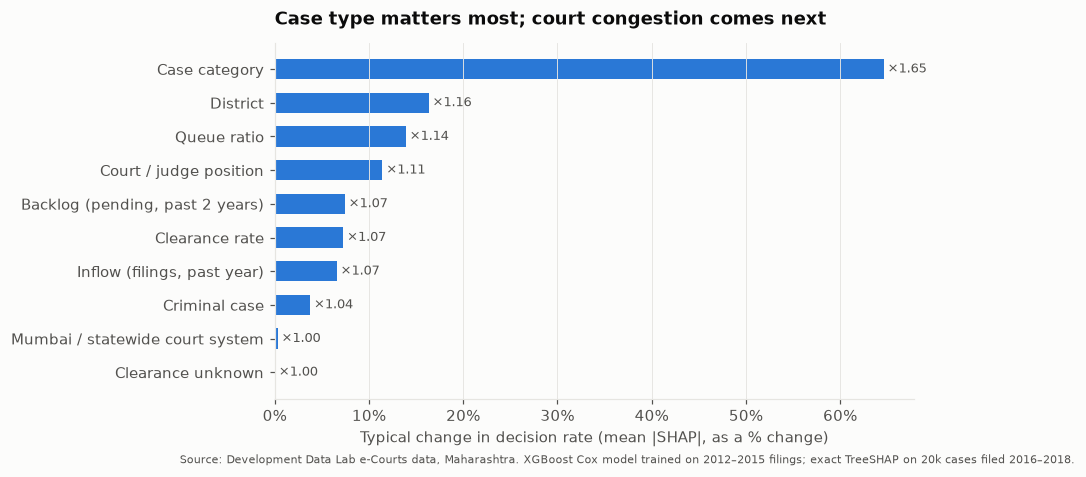

case_category        0.440
district_name        0.133
queue_ratio          0.115
judge_position       0.095
log_backlog          0.063
clearance_1y         0.062
log_inflow           0.056
is_criminal          0.032
court_system         0.003
clearance_missing    0.000
Name: share of total |SHAP|, dtype: float32

In [3]:
imp = feat.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh([LABELS[c] for c in imp.index], np.exp(imp.values) - 1, color=BLUE, height=0.6)
for i, v in enumerate(imp.values):
    ax.text(np.exp(v) - 1, i, f" ×{np.exp(v):.2f}", va="center", fontsize=8.5, color=INK2)
ax.xaxis.set_major_formatter(mt.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Typical change in decision rate (mean |SHAP|, as a % change)")
ax.set_title("Case type matters most; court congestion comes next")
finish(fig, "14_shap_importance")
(imp.sort_values(ascending=False) / imp.sum()).round(3).rename("share of total |SHAP|")

## 2. Court congestion

Each dot is a case; the line is the median SHAP value in 20 bins of the feature. Inflow and
backlog are plotted on their original scale (cases).

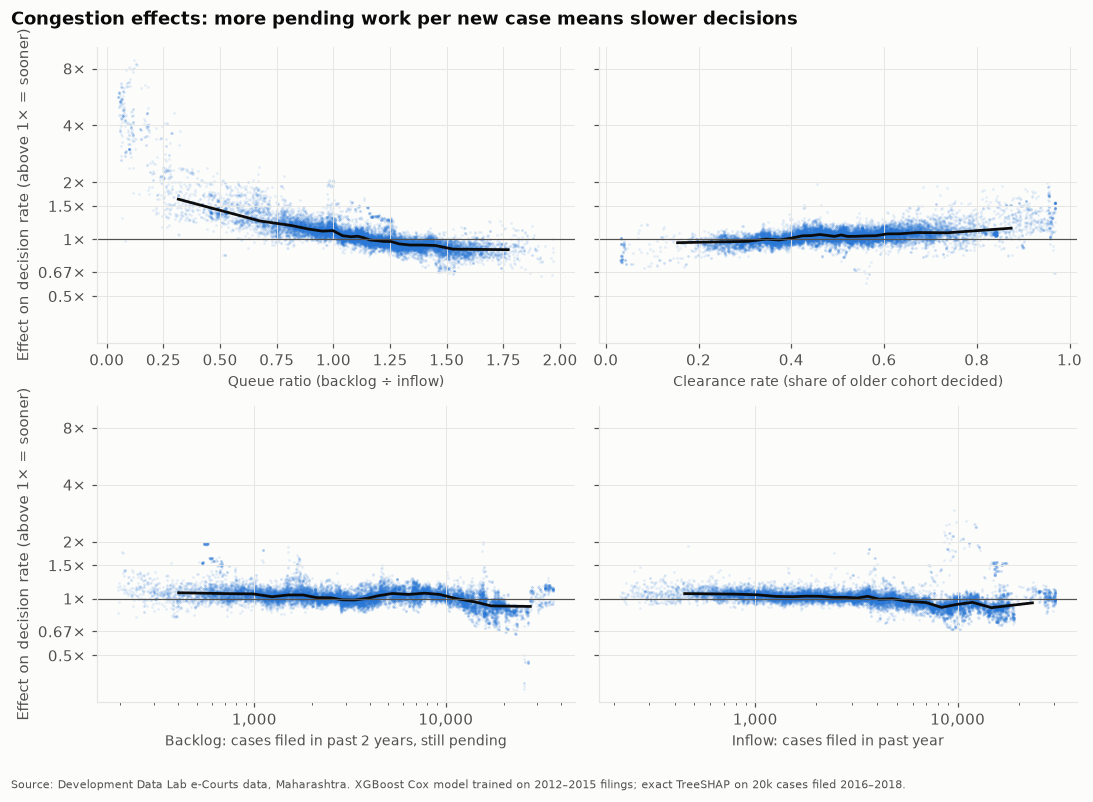

In [4]:
spec = [("queue_ratio", "Queue ratio (backlog ÷ inflow)", False),
        ("clearance_1y", "Clearance rate (share of older cohort decided)", False),
        ("log_backlog", "Backlog: cases filed in past 2 years, still pending", True),
        ("log_inflow", "Inflow: cases filed in past year", True)]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for ax, (c, label, logx) in zip(axes.ravel(), spec):
    x = ev[c].to_numpy(float)
    x = np.expm1(x) if logx else x
    y = np.exp(feat[c].to_numpy())
    lo, hi = np.quantile(x, [0.005, 0.995])
    keep = (x >= lo) & (x <= hi)
    ax.scatter(x[keep], y[keep], s=3, color=BLUE, alpha=0.12, linewidths=0, rasterized=True)
    bins = np.unique(np.quantile(x[keep], np.linspace(0, 1, 21)))
    b = pd.Series(y[keep]).groupby(pd.cut(x[keep], bins, include_lowest=True), observed=True).median()
    mid = [iv.mid for iv in b.index]
    ax.plot(mid, b.values, color=INK, linewidth=1.8)
    ax.axhline(1, color=INK2, linewidth=0.8)
    if logx:
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_yscale("log")
    mult_axis(ax.yaxis)
    ax.set_xlabel(label, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Effect on decision rate (above 1× = sooner)")
fig.suptitle("Congestion effects: more pending work per new case means slower decisions",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
finish(fig, "15_shap_congestion")

## 3. Case category and district

Average SHAP value per group, as a decision-rate multiplier relative to the average case. These
are model-based effects with congestion and the other features held in the model, so the district
effects can be compared with the Week 3 adjusted ranking (figure 08).

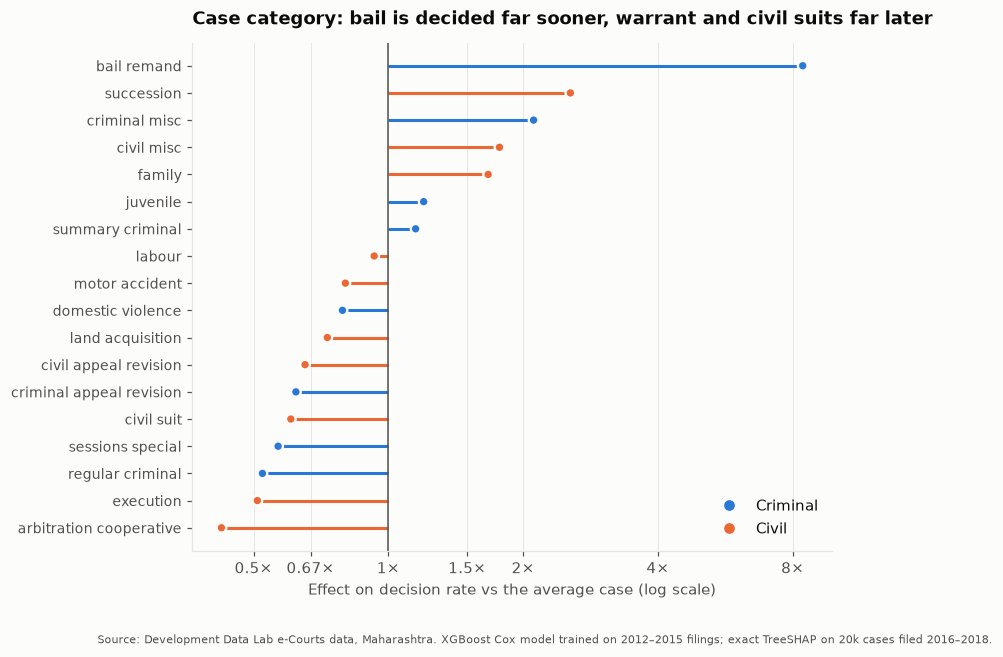

,m,n,crim
case_category,,,
bail_remand,8.42,934,True
succession,2.55,65,False
criminal_misc,2.11,2751,True
civil_misc,1.77,931,False
family,1.67,762,False
juvenile,1.20,109,True
summary_criminal,1.15,7738,True
labour,0.93,326,False
motor_accident,0.80,417,False


In [5]:
cat = pd.DataFrame({"m": np.exp(feat["case_category"].groupby(ev["case_category"], observed=True).mean()),
                    "n": ev.groupby("case_category", observed=True).size(),
                    "crim": ev.groupby("case_category", observed=True)["is_criminal"].mean() > 0.5})
cat = cat[cat.n >= 50].sort_values("m")
fig, ax = plt.subplots(figsize=(7.5, 6))
y = np.arange(len(cat))
col = np.where(cat.crim, BLUE, ORANGE)
ax.hlines(y, 1, cat.m, color=col, linewidth=2)
ax.scatter(cat.m, y, color=col, s=40, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(1, color=INK2, linewidth=1)
ax.set_xscale("log")
mult_axis(ax.xaxis)
ax.set_yticks(y, cat.index.str.replace("_", " "), fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect on decision rate vs the average case (log scale)")
ax.legend([plt.Line2D([], [], marker="o", color=BLUE, linestyle=""),
           plt.Line2D([], [], marker="o", color=ORANGE, linestyle="")], ["Criminal", "Civil"],
          loc="lower right")
ax.set_title("Case category: bail is decided far sooner, warrant and civil suits far later")
finish(fig, "16_shap_category")
cat.assign(m=cat.m.round(2)).sort_values("m", ascending=False)

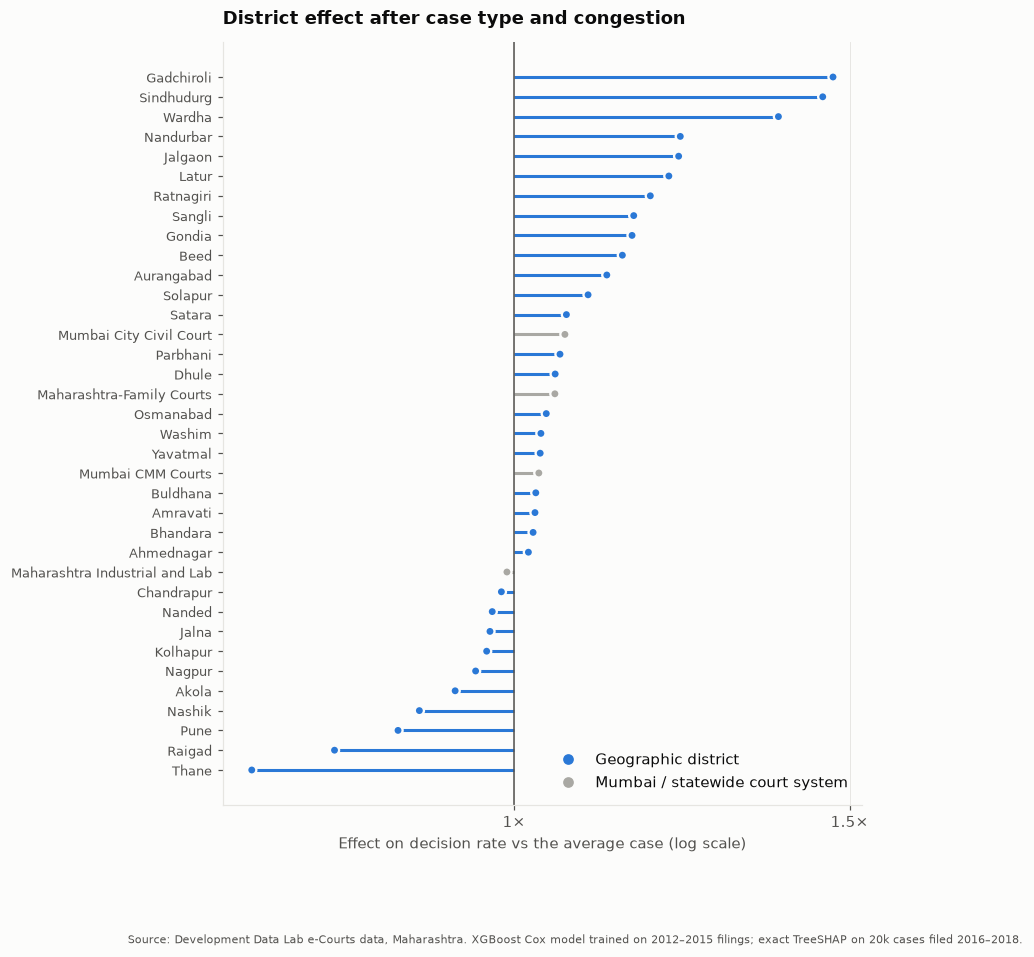

,m,n,court_system
district_name,,,
Thane,0.73,1211,False
Raigad,0.80,386,False
Pune,0.87,1302,False
Nashik,0.89,863,False
Akola,0.93,439,False
Nagpur,0.95,1237,False
Kolhapur,0.97,520,False
Jalna,0.97,288,False
Nanded,0.97,454,False


In [6]:
dist = pd.DataFrame({"m": np.exp(feat["district_name"].groupby(ev["district_name"], observed=True).mean()),
                     "n": ev.groupby("district_name", observed=True).size()})
dist = dist[dist.n >= 100].sort_values("m")
dist["court_system"] = M.is_court_system(dist.index.to_series()).values
fig, ax = plt.subplots(figsize=(7.5, 9))
y = np.arange(len(dist))
col = np.where(dist.court_system, MUTED, BLUE)
ax.hlines(y, 1, dist.m, color=col, linewidth=2)
ax.scatter(dist.m, y, color=col, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(1, color=INK2, linewidth=1)
ax.set_xscale("log")
mult_axis(ax.xaxis)
ax.set_yticks(y, dist.index, fontsize=8.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect on decision rate vs the average case (log scale)")
ax.legend([plt.Line2D([], [], marker="o", color=BLUE, linestyle=""),
           plt.Line2D([], [], marker="o", color=MUTED, linestyle="")],
          ["Geographic district", "Mumbai / statewide court system"], loc="lower right")
ax.set_title("District effect after case type and congestion")
finish(fig, "17_shap_district")
dist.round(2).sort_values("m")

## 4. One case, explained

A worked example: the prediction for a single regular civil suit, broken into feature
contributions. This is the explanation the `/predict` API can return with each curve.

                         78
year                   2016
district_name          Pune
judge_position  civil court
case_category    civil_suit
queue_ratio        1.584351
clearance_1y       0.253889
predicted median: beyond 2 years (average test case: 495 days); overall rate multiplier ×0.32


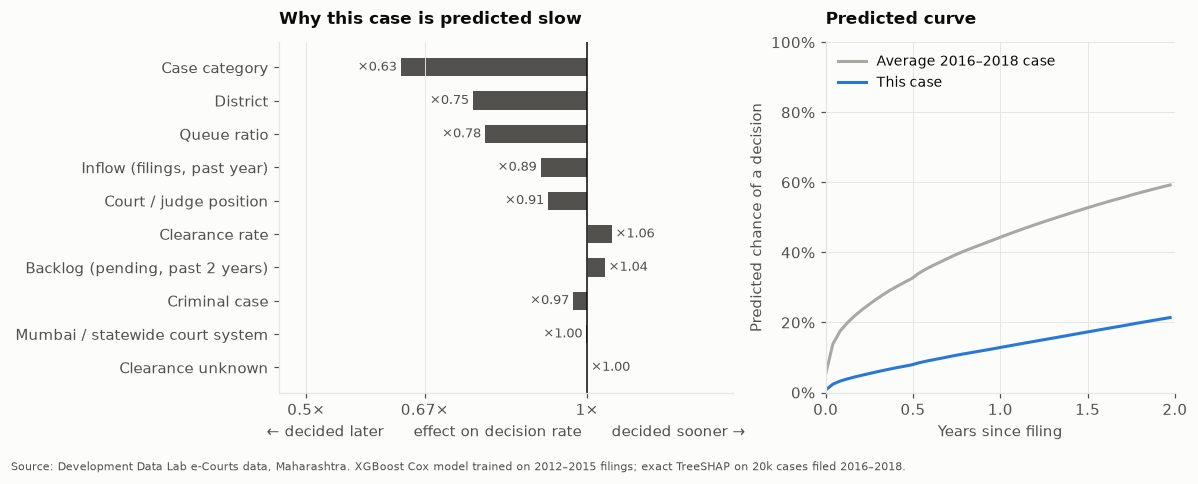

In [7]:
pick = ev[(ev.case_category == "civil_suit") & (ev.district_name == "Pune")].index[0]
row = ev.loc[[pick]]
contrib = feat.loc[pick].sort_values(key=np.abs)
surv1 = model.predict_survival(row)[0]
avg = model.predict_survival(ev).mean(axis=0)
med_case, med_avg = M.median_days(surv1[None])[0], M.median_days(avg[None])[0]
print(row[["year", "district_name", "judge_position", "case_category", "queue_ratio", "clearance_1y"]].T)
fmt = lambda d: "beyond 2 years" if np.isnan(d) else f"{d:.0f} days"
print(f"predicted median: {fmt(med_case)} (average test case: {fmt(med_avg)}); "
      f"overall rate multiplier ×{np.exp(contrib.sum()):.2f}")

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
m = np.exp(contrib.values)
ax.barh([LABELS[c] for c in contrib.index], m - 1, left=1, color=INK2, height=0.55)
for i, v in enumerate(m):
    ax.text(v, i, f" ×{v:.2f} ", va="center", ha="left" if v >= 1 else "right",
            fontsize=8.5, color=INK2)
ax.axvline(1, color=INK, linewidth=1)
ax.set_xscale("log")
ax.set_xlim(min(m.min(), 1) / 1.35, max(m.max(), 1) * 1.35)   # room for the value labels
mult_axis(ax.xaxis)
ax.grid(axis="y", visible=False)
ax.set_xlabel("← decided later      effect on decision rate      decided sooner →")
ax.set_title("Why this case is predicted slow", fontsize=11)
ax2.plot(M.GRID / 365, 1 - avg, color=MUTED, label="Average 2016–2018 case")
ax2.plot(M.GRID / 365, 1 - surv1, color=BLUE, label="This case")
ax2.yaxis.set_major_formatter(mt.PercentFormatter(1))
ax2.set_xlim(0, 2)
ax2.set_ylim(0, 1)
ax2.set_xlabel("Years since filing")
ax2.set_ylabel("Predicted chance of a decision")
ax2.legend(loc="upper left", fontsize=9)
ax2.set_title("Predicted curve", fontsize=11)
fig.tight_layout()
finish(fig, "18_shap_example")

## Summary

- **Case category dominates** (44% of total |SHAP|): bail applications are decided at 8.4× the
  average case's rate, arbitration/co-operative disputes, execution petitions and regular warrant
  cases at about 0.4–0.5×.
- **Court congestion is the second block** (queue ratio 12%, backlog, clearance and inflow 6% each:
  about 30% together, more than district at 13%). The queue ratio has a clear dose-response: a
  court whose two-year backlog is a quarter of its yearly inflow decides cases about 1.6× faster
  than average, one at 1.5–1.75 about 0.9×. A higher clearance rate in the court's older cohort
  means faster decisions.
- **District effects mostly survive** the congestion features (rank correlation 0.81 with the
  Week 3 Cox ranking): Thane, Raigad and Pune slowest, Gadchiroli, Sindhudurg and Wardha fastest.
  **Nagpur** is the exception: 5th fastest in Week 3 but 27th of 32 here, so its speed comes from
  lightly loaded courts rather than from anything district-specific.
- **One case:** a 2016 civil suit in Pune is predicted to be decided at 0.32× the average rate
  (median beyond 2 years): its case type, district, and a crowded court (queue ratio 1.58) all
  push it later.

SHAP explains the model, not causes: congestion and district are correlated, and the model splits
credit between them.